In [2]:
from rdkit import Chem
import pickle
import os
import json
import joblib
import numpy as np
import xgboost


In [3]:
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}

In [4]:
reactions_dir = "reactions"
reaction_id = 22
reaction_dir = os.path.join(reactions_dir, str(reaction_id))
mol_objects = []

for root, dirs, files in os.walk(reaction_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")

print(f"Converted {len(mol_objects)} pickle files to RDKit Mol objects.")

Converted 4 pickle files to RDKit Mol objects.


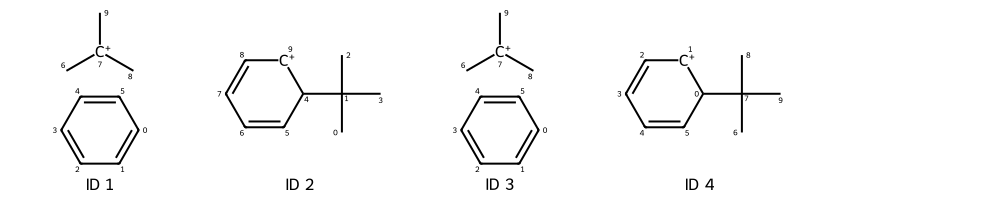

In [5]:
opt = Chem.Draw.MolDrawOptions()
opt.addAtomIndices = True
Chem.Draw.MolsToGridImage(mol_objects, molsPerRow=5, subImgSize=(200, 200), legends=[f"ID {i+1}" for i in range(len(mol_objects))], drawOptions=opt)

In [6]:
mol_arom = mol_objects[0]
Chem.SanitizeMol(mol_arom)
for a in mol_arom.GetAromaticAtoms():
    print(a.GetIdx())

0
1
2
3
4
5


In [7]:
training_id = 16
training_dir = os.path.join("training", str(training_id))
t_mol_objects = []

for root, dirs, files in os.walk(training_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        if file == "sm.pkl":
                            sm = mol
                        else:
                            t_mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    
with open(os.path.join(training_dir,'data.json'), 'r') as file:
    data = json.load(file)

t_mol_objects = [sm] + t_mol_objects

print(f"Converted {len(t_mol_objects)} pickle files to RDKit Mol objects.")
print(data)

Converted 19 pickle files to RDKit Mol objects.
{'choices': {'0': {'mechanism': [6, 0, 7, None, None], 'probable': 1}, '1': {'mechanism': [7, 0, 11, None, 12], 'probable': 0}, '2': {'mechanism': [7, 0, 12, None, 11], 'probable': 0}, '3': {'mechanism': [5, 11, 6, 12, None], 'probable': 0}, '4': {'mechanism': [5, 12, 6, 11, None], 'probable': 0}, '5': {'mechanism': [1, 11, 7, 12, None], 'probable': 0}, '6': {'mechanism': [1, 12, 7, 11, None], 'probable': 0}, '7': {'mechanism': [5, 11, 8, 12, None], 'probable': 0}, '8': {'mechanism': [5, 12, 8, 11, None], 'probable': 0}, '9': {'mechanism': [5, 3, 6, 0, None], 'probable': 0}, '10': {'mechanism': [1, 3, 7, 0, None], 'probable': 0}, '11': {'mechanism': [5, 3, 8, 0, None], 'probable': 0}, '12': {'mechanism': [5, 8, 6, 0, None], 'probable': 0}, '13': {'mechanism': [1, 8, 7, 0, None], 'probable': 0}, '14': {'mechanism': [3, 3, 11, 0, 12], 'probable': 0}, '15': {'mechanism': [3, 3, 12, 0, 11], 'probable': 0}, '16': {'mechanism': [3, 8, 11, 0, 12

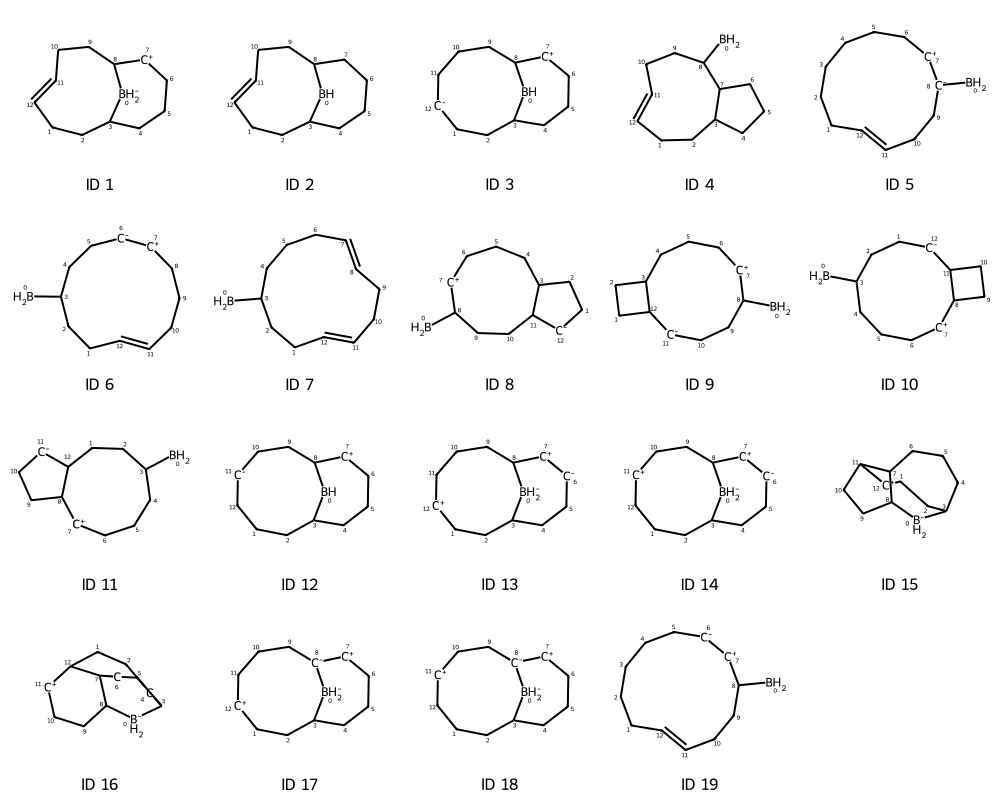

In [8]:
Chem.Draw.MolsToGridImage(t_mol_objects, molsPerRow=5, subImgSize=(200, 200), legends=[f"ID {i+1}" for i in range(len(t_mol_objects))], drawOptions=opt)

In [9]:
def make_atom_fingerprint(atom):

    # Charge bitstring
    charge_bitstring = [0] * 3
    if atom.GetFormalCharge() < 0:
        charge_bitstring[0] = 1
    elif atom.GetFormalCharge() == 0:
        charge_bitstring[1] = 1
    elif atom.GetFormalCharge() > 0:
        charge_bitstring[2] = 1

    # H bitstring
    h_number_bitstring = [0] * 4
    if atom.GetTotalNumHs() == 0:
        h_number_bitstring[0] = 1
    elif atom.GetTotalNumHs() == 1:
        h_number_bitstring[1] = 1
    elif atom.GetTotalNumHs() == 2:
        h_number_bitstring[2] = 1
    elif atom.GetTotalNumHs() > 2:
        h_number_bitstring[3] = 1

    # Hybridization bitstring
    hybridization_bitstring = [0] * 3
    if atom.GetHybridization() == Chem.rdchem.HybridizationType.SP:
        hybridization_bitstring[0] = 1
    elif atom.GetHybridization() == Chem.rdchem.HybridizationType.SP2:
        hybridization_bitstring[1] = 1
    elif atom.GetHybridization() == Chem.rdchem.HybridizationType.SP3:
        hybridization_bitstring[2] = 1

    # Element bitstring
    # [AlkMet, B, C, N, O, F, Mg, Al, Si, P, S, Cl, Br, I, Met]
    ptable = Chem.GetPeriodicTable()
    element_bitstring = [0] * 15
    dict_elements = { 5: 1,
                      6: 2,
                      7: 3,
                      8: 4,
                      9: 5,
                      12: 6,
                      13: 7,
                      14: 8,
                      15: 9,
                      16: 10,
                      17: 11,
                      35: 12,
                      53: 13}
    atm_num = atom.GetAtomicNum()
    if atm_num in dict_elements:
        element_bitstring[dict_elements[atm_num]] = 1
    elif ptable.GetNOuterElecs(atm_num) == 1:
        element_bitstring[0] = 1
    elif atm_num <= 30 and atm_num >= 20:
        element_bitstring[14] = 1

    # aromaticity bitstring
    new_mol = Chem.Mol(atom.GetOwningMol())
    Chem.SetAromaticity(new_mol)
    if new_mol.GetAtomWithIdx(atom.GetIdx()).GetIsAromatic():
        aromatic_bit = [1]
    else:
        aromatic_bit = [0]

    # adjacency bitstring
    # [C+, C-, CH, C-EN, C=EN, EN, EP]
    adjecency_bitstring = [0] * 8
    for a in atom.GetNeighbors():
        if a.GetAtomicNum() == 6:
            if a.GetFormalCharge() > 0:
                adjecency_bitstring[0] = 1
            elif a.GetFormalCharge() < 0:
                adjecency_bitstring[1] = 1
            if a.GetTotalNumHs() > 0:
                adjecency_bitstring[2] = 1
            for a2 in a.GetNeighbors():
                if electronegativity_dict[a2.GetAtomicNum()] > 2.55:
                    for b in a.GetBonds():
                        if b.GetOtherAtom(a).GetIdx() == a2.GetIdx():
                            if b.GetBondTypeAsDouble() == 1:
                                adjecency_bitstring[3] = 1
                            elif b.GetBondTypeAsDouble() >= 2:
                                adjecency_bitstring[4] = 1
        elif electronegativity_dict[a.GetAtomicNum()] > 2.55:
            adjecency_bitstring[5] = 1
        elif electronegativity_dict[a.GetAtomicNum()] < 2.05:
            adjecency_bitstring[6] = 1
 
    

    total_bit_string = charge_bitstring + h_number_bitstring + hybridization_bitstring + element_bitstring + aromatic_bit + adjecency_bitstring
    return total_bit_string

   
def make_bond_fingerprint(bond):
    # bond type bitstring
    # [single, double, triple]
    bond_type_bitstring = [0] * 4
    if not bond:
        return bond_type_bitstring
    if bond.GetBondTypeAsDouble() == 1:
        bond_type_bitstring[0] = 1
    elif bond.GetBondTypeAsDouble() == 2:
        bond_type_bitstring[1] = 1
    elif bond.GetBondTypeAsDouble() == 3:
        bond_type_bitstring[2] = 1
    return bond_type_bitstring


def new_bond_fingerprint(mol, a1_idx, a2_idx):
    a1 = mol.GetAtomWithIdx(a1_idx)
    a2 = mol.GetAtomWithIdx(a2_idx)
    # ring size bitstring
    # [3, 4, 5, 6, 7+]
    ring_size_bitstring = [0] * 5
    fragments = Chem.GetMolFrags(mol)
    for f in fragments:
        if a1.GetIdx() in f and a2.GetIdx() in f:
            len_path = len(Chem.GetShortestPath(mol, a1.GetIdx(), a2.GetIdx()))
            if len_path == 3:
                ring_size_bitstring[0] = 1
            elif len_path == 4:
                ring_size_bitstring[1] = 1
            elif len_path == 5:
                ring_size_bitstring[2] = 1
            elif len_path == 6:
                ring_size_bitstring[3] = 1
            elif len_path >= 7:
                ring_size_bitstring[4] = 1
    return ring_size_bitstring


In [47]:
# Data analysis

arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
}


training_dir = "training"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []

for subdir in subdirs:
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    for id, info in choices.items():
        # bitvector for the mechanism
        mech_type = [0] * 8
        mech_type[info['mechanism'][0]] = 1
        if info['mechanism'][0] < 4 or True:
            a1 = make_atom_fingerprint(sm.GetAtomWithIdx(info['mechanism'][1]))
            a2 = make_atom_fingerprint(sm.GetAtomWithIdx(info['mechanism'][2]))
            if info['mechanism'][3]:
                b1 = make_bond_fingerprint(sm.GetBondBetweenAtoms(info['mechanism'][1], info['mechanism'][3]))
            else:
                b1 = [0] *4
            if info['mechanism'][4]:
                b2 = make_bond_fingerprint(sm.GetBondBetweenAtoms(info['mechanism'][2], info['mechanism'][4]))
            else:
                b2 = [0] *4
            r = new_bond_fingerprint(sm, info['mechanism'][1], info['mechanism'][2])
            sum_finger_print = mech_type + a1 + a2 + b1 + b2 + r
            bitvectors.append(sum_finger_print)
            outcomes.append(info['probable'])
            # Track the origin of each bitvector
            with open("bitvector_origins.txt", "a") as origin_file:
                origin_file.write(f"{len(bitvectors)-1},{training_dir}/{subdir},{id}\n")



In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score

In [82]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

# Logistic Regression classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
joblib.dump(clf, 'model.pkl')

Accuracy: 0.9322916666666666
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.99      0.96       173
           1       0.80      0.42      0.55        19

    accuracy                           0.93       192
   macro avg       0.87      0.70      0.76       192
weighted avg       0.93      0.93      0.92       192



['model.pkl']

In [69]:
m = Chem.MolFromSmiles('CCO')
Chem.GetShortestPath(m, 0, 1)
print(bool(m.GetBondBetweenAtoms(0,2)))

False


In [70]:
print(np.sum(np.array(outcomes)))

103


In [71]:
len(outcomes)

765

In [72]:
1 - 103/765

0.865359477124183

In [139]:
from xgboost import XGBClassifier

In [140]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


# XGBoost Regression classifier
clf = XGBClassifier(scale_pos_weight = 12, eval_metric='logloss')
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
joblib.dump(clf, 'xg_model.pkl')

              precision    recall  f1-score   support

           0       0.95      0.92      0.94       280
           1       0.59      0.71      0.65        45

    accuracy                           0.89       325
   macro avg       0.77      0.82      0.79       325
weighted avg       0.90      0.89      0.90       325



['xg_model.pkl']

In [131]:
precisions =[]
recalls = []
pos_weight = 15
iter = 10
for i in range(pos_weight):
    precision = 0
    recall = 0
    for k in range(iter):
        X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)
        clf = XGBClassifier(scale_pos_weight = i+1, eval_metric='logloss')
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        #print(classification_report(y_test, y_pred))
        recall += recall_score(y_test, y_pred)/iter
        precision += precision_score(y_test, y_pred)/iter
    precisions.append(precision)
    recalls.append(recall)


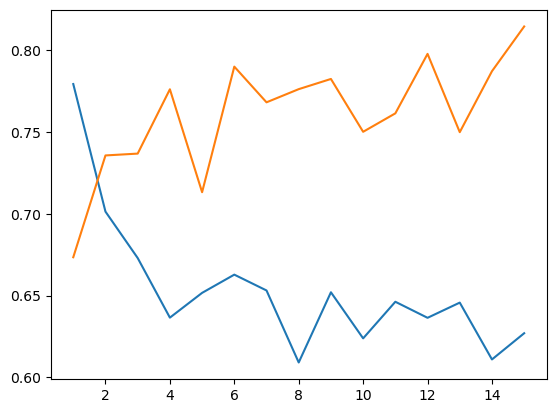

In [132]:
from matplotlib import pyplot as plt
plt.plot(range(1, pos_weight+1), precisions, label='Precision')
plt.plot(range(1, pos_weight+1), recalls, label='Recall')
plt.show()

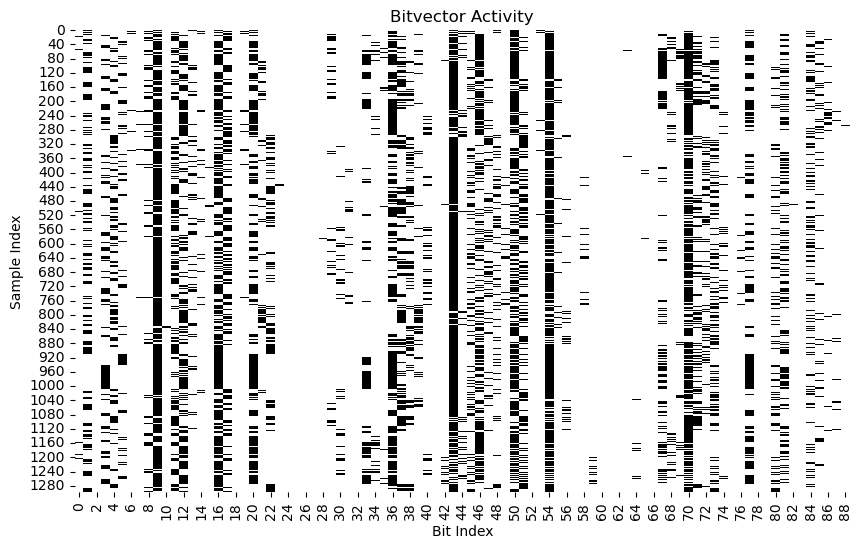

In [141]:
import seaborn as sns


plt.figure(figsize=(10, 6))
sns.heatmap(bitvectors, cmap="Greys", cbar=False)
plt.xlabel("Bit Index")
plt.ylabel("Sample Index")
plt.title("Bitvector Activity")
plt.show()

In [142]:
np.sum(np.array(bitvectors), axis=0)

array([  20,  395,    0,  341,  318,  203,    6,   15,  134, 1158,    6,
        493,  585,  166,   54,   12,  835,  451,    0,   21,  640,  124,
        283,    6,    0,    0,    0,    0,    2,   96,   95,   31,    0,
        284,   66,   35,  754,  406,  308,  124,  139,    0,   29, 1183,
         86,  279,  648,  184,  187,   41,  816,  441,    0,   19, 1083,
         51,   54,    0,   37,   19,    0,    0,    1,   12,   12,   10,
          0,  344,   99,   67,  982,  294,  221,  412,   57,    0,   36,
        514,    0,    0,  214,  451,    4,    0,  314,  160,   55,   26,
          7])

In [143]:
np.array(bitvectors).shape

(1298, 89)

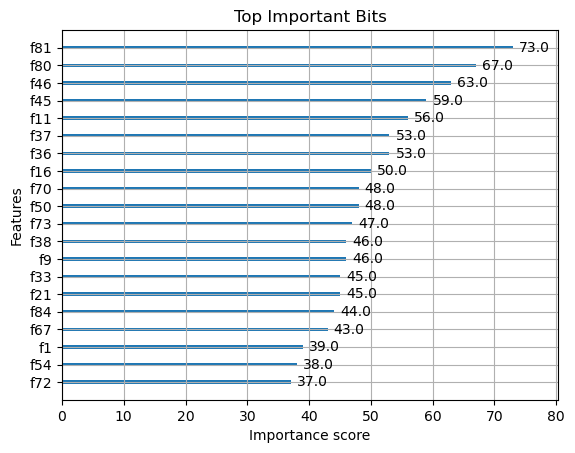

In [134]:
xgboost.plot_importance(clf, max_num_features=20)
plt.title("Top Important Bits")
plt.show()

In [107]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

# Logistic Regression classifier
clf = RandomForestClassifier(
    n_estimators=100,     # number of trees
    max_depth=None,       # let trees grow until pure
    class_weight='balanced',  # helpful for imbalanced classes
    random_state=42
)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.8803088803088803
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.95      0.93       213
           1       0.70      0.57      0.63        46

    accuracy                           0.88       259
   macro avg       0.81      0.76      0.78       259
weighted avg       0.87      0.88      0.88       259



In [152]:
%run ml_tools/get_feature.py 1

Feature at index 1: Mechanism Type Bit


In [154]:
import shap

/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/shap/plots/_beeswarm.py:1153: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  pl.tight_layout()


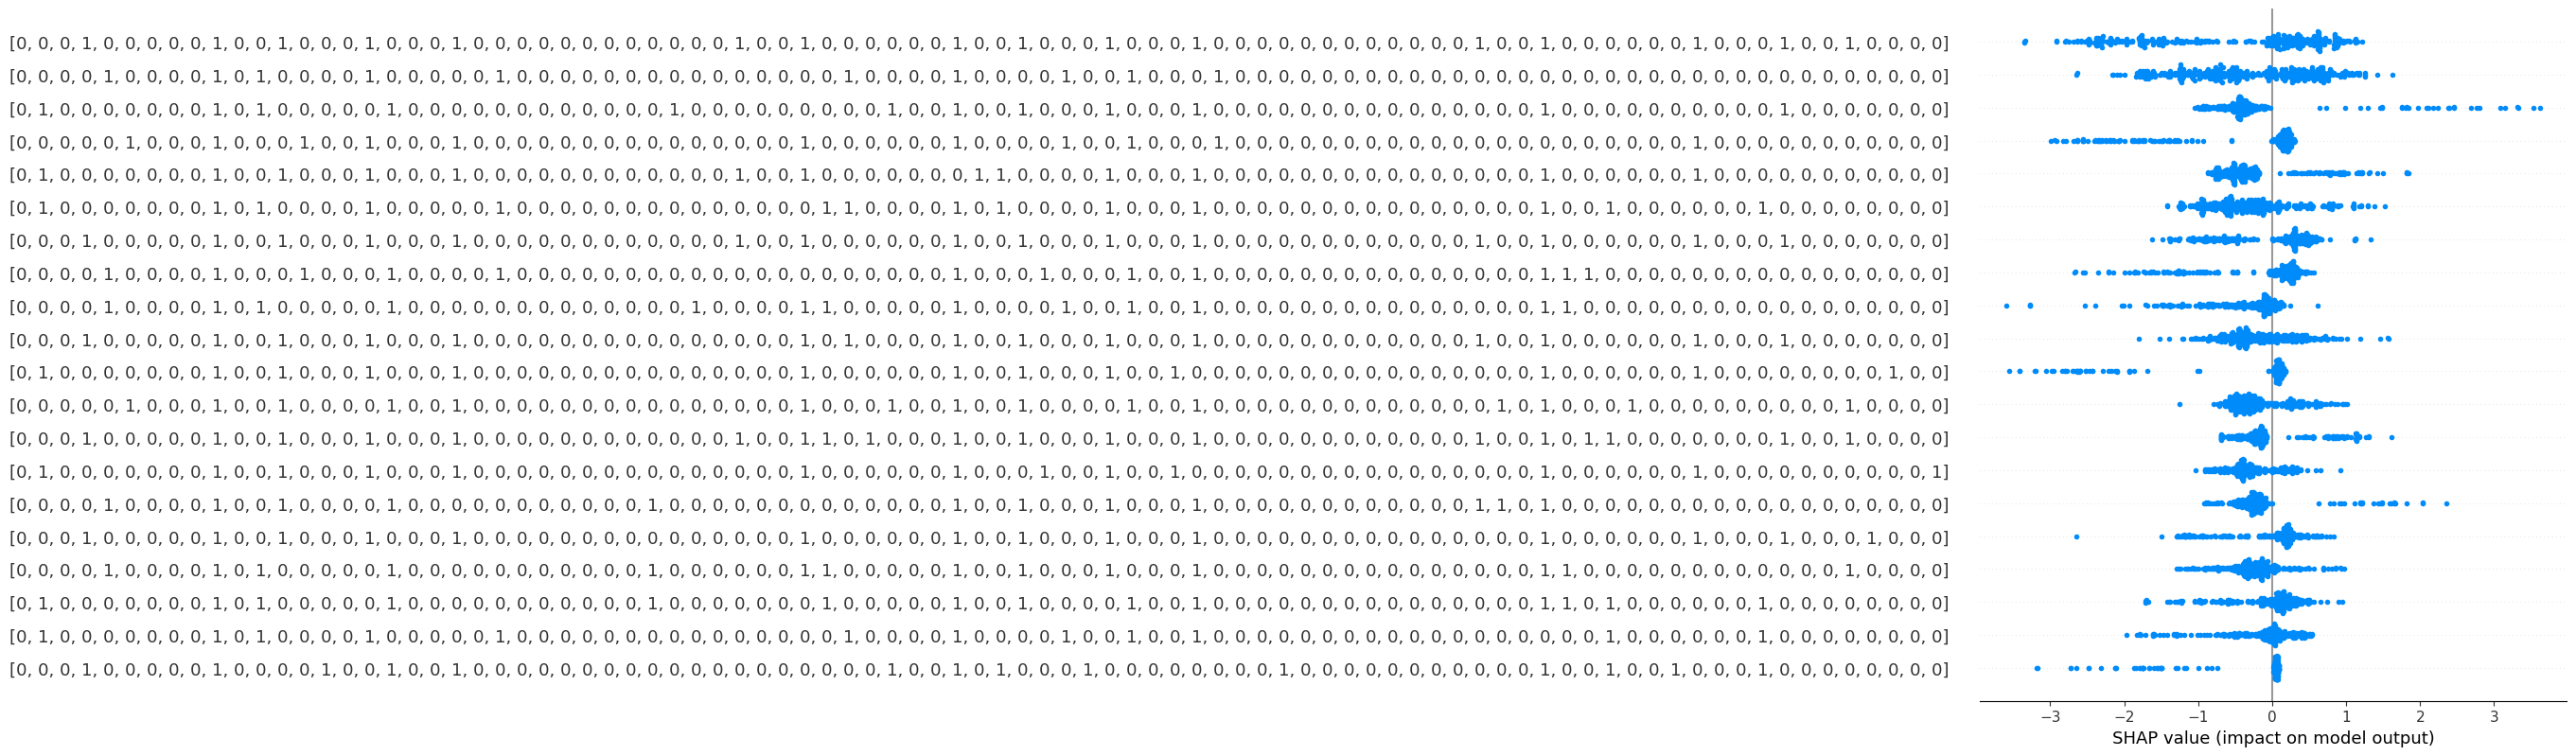

In [159]:
explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

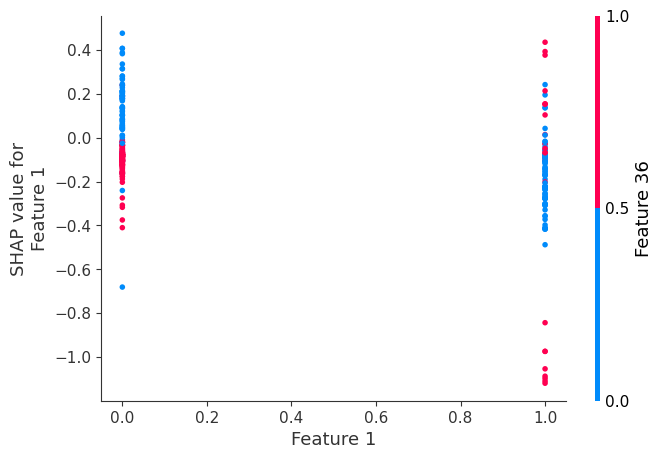

In [167]:
shap.dependence_plot(1, shap_values, np.array(X_test))

Can we learn chemical reactions from the reaction space

In [41]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances


mask = np.array(outcomes) == 1
X = np.array(bitvectors)[mask]


# Use Jaccard distance
distances = pairwise_distances(np.array(bitvectors), metric='jaccard')

# Fit kNN using precomputed distances
knn = NearestNeighbors(n_neighbors=2, metric='precomputed')
knn.fit(distances)

# Find nearest neighbors of a specific vector
dists, indices = knn.kneighbors([distances[0]])
print("Nearest neighbors of first bitstring:", indices)

Nearest neighbors of first bitstring: [[0 7]]


/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [42]:
from sklearn.cluster import DBSCAN

# Compute Jaccard distance matrix
dist = pairwise_distances(X, metric='jaccard')

# Cluster using DBSCAN
clustering = DBSCAN(metric='precomputed', eps=0.2, min_samples=3)
labels = clustering.fit_predict(dist)

print("Cluster labels:", labels)

Cluster labels: [ 0  0  1  0  1 -1 -1 -1  2 -1 -1 -1  3  3 -1 -1 -1  1  4  4  4  4  1  4
  1 -1 -1 -1 -1 -1  3 -1 -1 -1 -1 -1  5 -1  6 -1  5  7  5  8  9 10 11  7
  5 -1 -1  7 -1  5  7 -1 -1  5  7  6  6 -1 -1  5  5 -1 -1 -1  5 -1 -1 -1
 -1 -1  6  5 12  8  5 10 11 -1 -1 -1 -1  5  9 -1  5 -1  9 10 -1  5 12 -1
  9  7  5 -1  7 -1 -1 -1 -1 -1 -1  5 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 12 -1 -1  5 -1 -1  7 -1 -1  3  5  9  9  9  7  7  7  7  7
  7  7  7  7  7  7  8 11 -1  3  3 -1 -1 -1 -1 -1 -1 -1 -1  2 -1 -1 -1 -1
 -1 -1  2 -1  5 -1 -1]


/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [43]:
len(labels)

175

In [44]:
len(bitvectors)

1298

In [45]:
from collections import defaultdict

clusters = defaultdict(list)
for idx, label in enumerate(labels):
    clusters[label].append(idx)

for cluster_id, members in clusters.items():
    if cluster_id == -1:
        print(f"Noise points: {members}")
    else:
        print(f"Cluster {cluster_id}: {members}")

Cluster 0: [0, 1, 3]
Cluster 1: [2, 4, 17, 22, 24]
Noise points: [5, 6, 7, 9, 10, 11, 14, 15, 16, 25, 26, 27, 28, 29, 31, 32, 33, 34, 35, 37, 39, 49, 50, 52, 55, 56, 61, 62, 65, 66, 67, 69, 70, 71, 72, 73, 81, 82, 83, 84, 87, 89, 92, 95, 99, 101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 126, 127, 129, 130, 132, 133, 152, 155, 156, 157, 158, 159, 160, 161, 162, 164, 165, 166, 167, 168, 169, 171, 173, 174]
Cluster 2: [8, 163, 170]
Cluster 3: [12, 13, 30, 134, 153, 154]
Cluster 4: [18, 19, 20, 21, 23]
Cluster 5: [36, 40, 42, 48, 53, 57, 63, 64, 68, 75, 78, 85, 88, 93, 98, 107, 128, 135, 172]
Cluster 6: [38, 59, 60, 74]
Cluster 7: [41, 47, 51, 54, 58, 97, 100, 131, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149]
Cluster 8: [43, 77, 150]
Cluster 9: [44, 86, 90, 96, 136, 137, 138]
Cluster 10: [45, 79, 91]
Cluster 11: [46, 80, 151]
Cluster 12: [76, 94, 125]


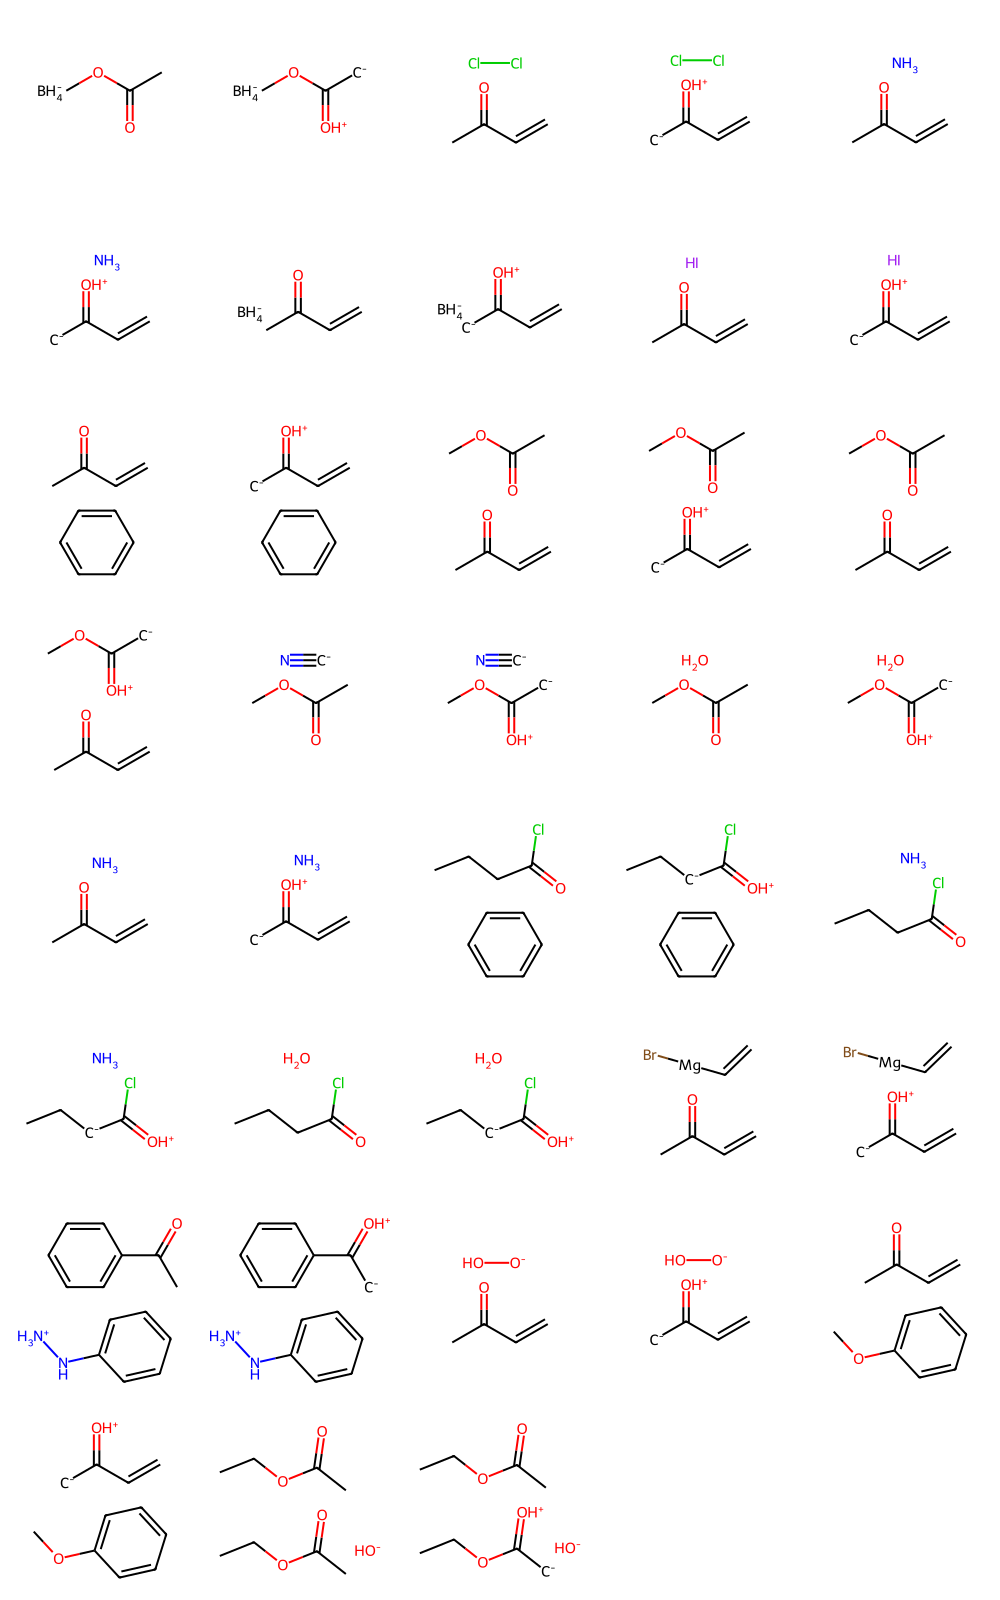

In [58]:
from rdkit.Chem import Draw

# Select a specific cluster to visualize (e.g., cluster_id)
cluster_members = clusters[5]

# For each member index, find the corresponding training directory

mols = []
legends = []
# subdirs is sorted list of training subdirectory names (as strings)
# cluster_members contains indices into the mask-filtered X (i.e., indices of probable outcomes)
# We need to map these indices back to the original subdirs

# First, get the indices of all probable outcomes in the original bitvectors list
probable_indices = np.where(mask)[0]

for idx in cluster_members:
    # Use bitvector_origins.txt to map idx to folder and choice id
    with open("bitvector_origins.txt", "r") as origin_file:
        for line in origin_file:
            parts = line.strip().split(",")
            if int(parts[0]) == probable_indices[idx]:
                folder_path = parts[1]
                subdir = os.path.basename(folder_path)
                mol_id = parts[2]
                break
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    mol_path = os.path.join(folder_path,  "mol_" + str(mol_id) + '.pkl')
    json_path = os.path.join(folder_path, 'data.json')
    # Load molecule
    with open(pkl_path, "rb") as f:
        mol = pickle.load(f)
        mols.append(mol)
    # Load probable mechanism info
    with open(mol_path, 'rb') as f:
        mol = pickle.load(f)
        mols.append(mol)
    legends.append(f"ID {subdir}")

# Visualize molecules with legends
Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(200, 200))